#### 1. The Normal Equation

In [1]:
import numpy as np

np.random.seed(42)
m = 100 # number of instances
X = 2 * np.random.rand(m,1) # column vector
y = 4 + 5* X + np.random.randn(m,1)

In [2]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X) # adding an column vector of value 1.
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

In [3]:
theta_best

array([[4.21509616],
       [4.77011339]])

In [4]:
X_new = np.array([[0],[2]])
X_new_b = add_dummy_feature(X_new) # adding a column vector of value 1.
y_predict = X_new_b @ theta_best
y_predict 

array([[ 4.21509616],
       [13.75532293]])

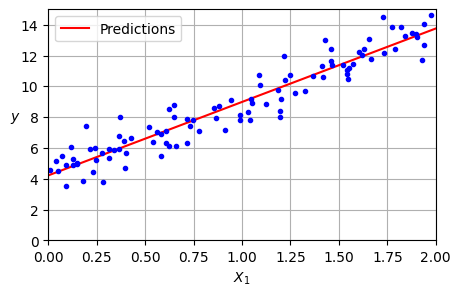

In [5]:
## Plot this models predictons:
import matplotlib.pyplot as plt

plt.figure(figsize = (5,3))
plt.plot(X_new, y_predict, 'r-', label = 'Predictions')
plt.plot(X, y , "b.")

# additional code for beutifying:
plt.xlabel("$X_1$")
plt.ylabel("$y$", rotation = 0)
plt.axis([0,2,0, 15])
plt.grid()
plt.legend(loc="upper left")
plt.show()

In [6]:
# Predicting parameter's using Linear regression
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X,y)
lin_reg.intercept_, lin_reg.coef_

(array([4.21509616]), array([[4.77011339]]))

In [7]:
lin_reg.predict(X_new)

array([[ 4.21509616],
       [13.75532293]])

### Important Note:
- scikit-learn Linear Regression model uses pseudoinverse to estimate the parameters instead of normal equation, because sometimes when X`X matrix is not invertible finding parameters using normal equation is impossible. For more: refer to the book or youtube videos.

#### 2. Gradient Descent

#####    Batch gradient descent

In [8]:
eta = 0.01 #learning rate
n_epochs = 10000 # total iteration
m = len(X_b)

np.random.seed(42)
theta = np.random.randn(2,1) # randomly initialized model parameters.

for epoch in range(n_epochs):
    gradients = 2/m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

theta # values are almost equivalent to above outcomes.

array([[4.21509616],
       [4.77011339]])

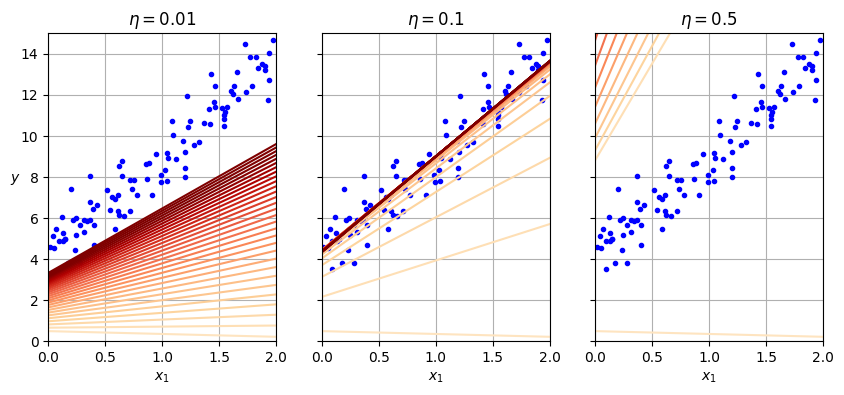

In [9]:
# extra code – generates Figures for different learning rate.
import matplotlib as mpl

def plot_gradient_descent(theta, eta):
    m = len(X_b)
    plt.plot(X, y, "b.")
    n_epochs = 1000
    n_shown = 30
    theta_path = []
    for epoch in range(n_epochs):
        if epoch < n_shown:
            y_predict = X_new_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(epoch / n_shown + 0.15))
            plt.plot(X_new, y_predict, linestyle="solid", color=color)
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
        theta_path.append(theta)
    plt.xlabel("$x_1$")
    plt.axis([0, 2, 0, 15])
    plt.grid()
    plt.title(fr"$\eta = {eta}$")
    return theta_path


np.random.seed(42)
theta = np.random.randn(2, 1)  # random initialization

plt.figure(figsize= (10,4))
plt.subplot(131)
plot_gradient_descent(theta, eta = 0.01)
plt.ylabel("$y$", rotation = 0)

plt.subplot(132)
plot_gradient_descent(theta, eta = 0.1)
plt.gca().axes.yaxis.set_ticklabels([])

plt.subplot(133)
plot_gradient_descent(theta, eta = 0.5)
plt.gca().axes.yaxis.set_ticklabels([])

plt.show()

##### Stochastic Gradient Descent

In [10]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0=0.01,
                       n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())  # y.ravel() because fit() expects 1D targets

SGDRegressor(n_iter_no_change=100, penalty=None, random_state=42, tol=1e-05)

In [11]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.2151219]), array([4.77060552]))

#### 3. Polynomial regression

In [12]:
np.random.seed(42)
m = 100
X = 6* np.random.rand(m,1) -3
y = 0.5 * X**2 + X + 2 + np.random.randn(m,1) # 2nd degree ploynomial with some noise.

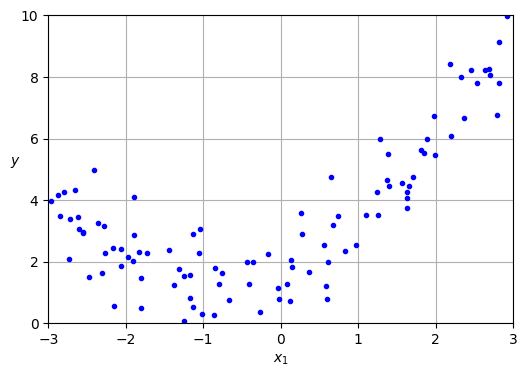

In [13]:
# extra code – 
plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

In [14]:
from sklearn.preprocessing import PolynomialFeatures

poly_features = PolynomialFeatures(degree = 2, include_bias= False)
X_poly = poly_features.fit_transform(X)


In [15]:
X[1]

array([2.70428584])

In [16]:
X_poly[1]

array([2.70428584, 7.3131619 ])

In [17]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
lin_reg.intercept_ , lin_reg.coef_ # coefficient of respectively X and X^2.

(array([1.78134581]), array([[0.93366893, 0.56456263]]))

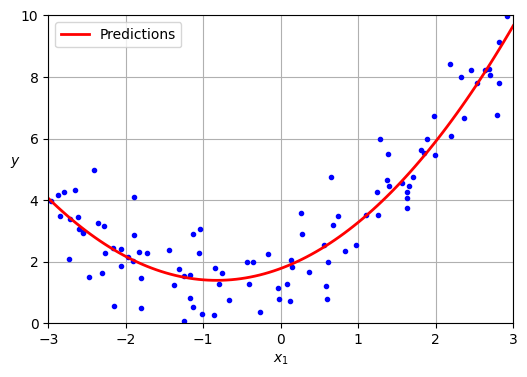

In [18]:
# extra_code
X_new = np.linspace(-3, 3, 100).reshape(100, 1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

#### 4. Learning Curves

#### 5. Regularized linear models

##### i) Ridge regression

In [19]:
np.random.seed(42)
m = 20
X = 3 * np.random.rand(m, 1)
y = 1 + 0.5 * X + np.random.randn(m, 1) / 1.5
X_new = np.linspace(0, 3, 100).reshape(100, 1)

In [20]:
## using closed form equation approach.
from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha = 0.1, solver = 'cholesky')
ridge_reg.fit(X,y)
ridge_reg.predict([[1.5]])

array([[1.55325833]])

In [21]:
### using stochastic gradient descent.
sgd_reg = SGDRegressor(penalty= 'l2', alpha = 0.1/m, tol = None,
                       max_iter= 1000,  random_state= 42)
sgd_reg.fit(X,y.ravel())
sgd_reg.predict([[1.5]])

array([1.55302613])

In [22]:
# -- shows the closed form solution of Ridge regression,
#              compare with the next Ridge model's learned parameters below
alpha = 0.1
A = np.array([[0., 0.], [0., 1.]])
X_b = np.c_[np.ones(m), X]
np.linalg.inv(X_b.T @ X_b + alpha * A) @ X_b.T @ y

array([[0.97898394],
       [0.3828496 ]])

In [23]:
ridge_reg.intercept_, ridge_reg.coef_  

(array([0.97898394]), array([[0.3828496]]))

##### ii) Lasso Regression

In [24]:
from sklearn.linear_model import Lasso

lasso_reg = Lasso(alpha = 0.1)
lasso_reg.fit(X,y)
lasso_reg.predict([[1.5]])

array([1.53788174])

##### iii) ElasticNet regression

In [25]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha = 0.1, l1_ratio= 0.5)
elastic_net.fit(X,y)
elastic_net.predict([[1.5]])

array([1.54333232])

##### iv) Early stopping

In [26]:
from copy import deepcopy
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
m = 100
X = 6 * np.random.rand(m,1) -3
y = 0.5*X **2 + X + 2 + np.random.randn(m,1)
# 50% data on validation set.
X_train, y_train = X[: m // 2], y[: m // 2, 0]
X_valid, y_valid = X[m // 2 :], y[m // 2 :, 0]

In [27]:
from sklearn.pipeline import make_pipeline

preprocessing  = make_pipeline(PolynomialFeatures(degree = 90, include_bias = False),
                               StandardScaler())

X_train_prep = preprocessing.fit_transform(X_train)
X_valid_prep = preprocessing.transform(X_valid)
sgd_reg = SGDRegressor(penalty = None, eta0 = 0.001, random_state = 42)
n_epochs = 1000
best_valid_rmse = float('inf')
train_errors, val_errors = [], []

for epoch in range(n_epochs):
    sgd_reg.partial_fit(X_train_prep, y_train)
    y_valid_predict = sgd_reg.predict(X_valid_prep)
    val_error = mean_squared_error(y_valid, y_valid_predict, squared = False)
    if val_error < best_valid_rmse:
        best_valid_rmse = val_error
        best_model = deepcopy(sgd_reg)

    # extra code – we evaluate the train error
    y_train_predict = sgd_reg.predict(X_train_prep)
    train_error = mean_squared_error(y_train, y_train_predict, squared = False)
    train_errors.append(train_error)
    val_errors.append(val_error)

    

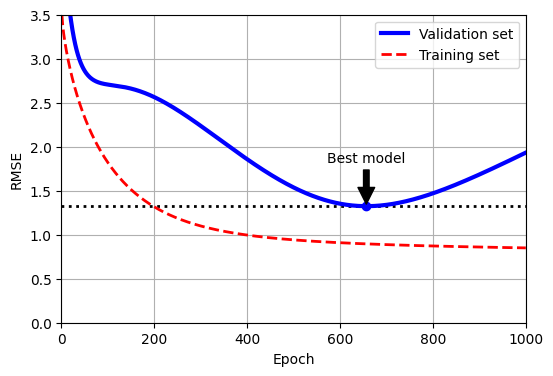

In [28]:
best_epoch = np.argmin(val_errors)
plt.figure(figsize=(6, 4))
plt.annotate('Best model',
             xy=(best_epoch, best_valid_rmse),
             xytext=(best_epoch, best_valid_rmse + 0.5),
             ha="center",
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.plot([0, n_epochs], [best_valid_rmse, best_valid_rmse], "k:", linewidth=2)
plt.plot(val_errors, "b-", linewidth=3, label="Validation set")
plt.plot(train_errors, "r--", linewidth = 2, label = "Training set")
plt.plot(best_epoch, best_valid_rmse, "bo")
plt.legend(loc="upper right")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.axis([0, n_epochs, 0, 3.5])
plt.grid()
plt.show()

#### 6. Logistic Regression

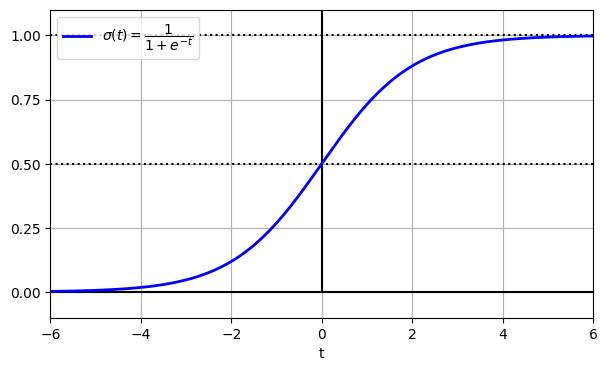

In [41]:
## Plotting sigmoid/logistic function:
lim = 6
t = np.linspace(-lim, lim, 200)
sig = 1/ (1+ np.exp(-t))

plt.figure(figsize= (7,4))
plt.plot([-lim, lim], [0,0], "k-")
plt.plot([-lim, lim], [1,1], "k:")
plt.plot([-lim, lim], [0.5,0.5], "k:")
plt.plot([0,0], [0, 1.1], "k-")
plt.plot(t, sig,"b-", linewidth = 2, label = r"$\sigma(t) = \dfrac{1}{1 + e^{-t}}$")
plt.xlabel("t")
plt.legend(loc = 'upper left')
plt.axis([-lim, lim, -0.1, 1.1])
plt.grid()
plt.gca().set_yticks([0, 0.25, 0.5, 0.75, 1])
plt.show()

In [42]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
list(iris)

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [46]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = iris.data[["petal width (cm)"]].values
y = iris.target_names[iris.target] == "virginica"
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42)

log_reg = LogisticRegression(random_state = 42)
log_reg.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [75]:
# log_reg.predict([[1.7]])
log_reg.predict(X_test)

array([False, False,  True, False, False, False, False,  True, False,
       False,  True, False, False, False, False, False,  True, False,
       False,  True, False,  True, False,  True,  True,  True,  True,
        True, False, False, False, False, False, False, False,  True,
       False, False])

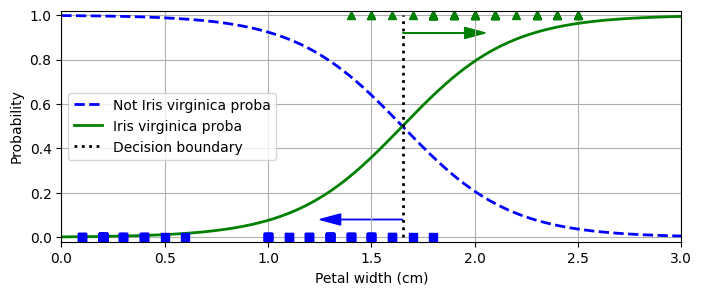

In [86]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)  # reshape to get a column vector
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

plt.figure(figsize=(8, 3))  # extra code – not needed, just formatting
plt.plot(X_new, y_proba[:, 0], "b--", linewidth=2,
         label="Not Iris virginica proba")
plt.plot(X_new, y_proba[:, 1], "g-", linewidth=2, label="Iris virginica proba")
plt.plot([decision_boundary, decision_boundary], [0, 1], "k:", linewidth=2,
         label="Decision boundary")

# extra code – this section beautifies and saves Figure 4–23
plt.arrow(x=decision_boundary, y=0.08, dx=-0.3, dy=0,
          head_width=0.05, head_length=0.1, fc="b", ec="b")
plt.arrow(x=decision_boundary, y=0.92, dx=0.3, dy=0,
          head_width=0.05, head_length=0.1, fc="g", ec="g")
plt.plot(X_train[y_train == 0], y_train[y_train == 0], "bs")
plt.plot(X_train[y_train == 1], y_train[y_train == 1], "g^")
plt.xlabel("Petal width (cm)")
plt.ylabel("Probability")
plt.legend(loc="center left")
plt.axis([0, 3, -0.02, 1.02])
plt.grid()

plt.show()

In [91]:
log_reg.predict([[1.3], [1.99]])

array([False,  True])

In [99]:
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

softmax_reg = LogisticRegression(C=0.02, random_state=42) 
# Note: here, C is a hyperparameter. Small C value applies strong regularization, whereas higher C values apply weak regularization(when we trust the data)
# Small C value: I do not trust the data source; higher C values i trust the data
softmax_reg.fit(X_train, y_train)

LogisticRegression(C=0.02, random_state=42)

In [96]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [98]:
softmax_reg.predict_proba([[5,2]]).round(3)

array([[0.085, 0.399, 0.516]])

In [100]:
softmax_reg2 = LogisticRegression(C=30, random_state=42)
softmax_reg2.fit(X_train, y_train)

softmax_reg2.predict_proba([[5,2]]).round(3)

array([[0.   , 0.041, 0.959]])

Notice the difference between them